# Применение Bernoulli Naive Bayes к бинаризованным признакам

**Предмет:** Основы машинного обучения

**Цель работы:** изучить наивный байесовский классификатор с распределением Бернулли, реализовать его с нуля, применить к данным, признаки которых предварительно бинаризованы, и исследовать, как на качество влияют способ/порог бинаризации и параметр сглаживания.

**План:**
1. Теория: модель Bernoulli NB и бинаризация.
2. Данные (`load_digits`) и разбиение.
3. Собственная реализация и проверка на совпадение с `sklearn.naive_bayes.BernoulliNB`.
4. Влияние порога бинаризации.
5. Влияние параметра сглаживания `alpha`.
6. Сравнение с другими моделями.
7. Анализ ошибок и интерпретация параметров модели.
8. Второй датасет (`load_breast_cancer`): бинаризация по медиане каждого признака.
9. Выводы.

## 1. Теория

**Наивный байесовский классификатор** выбирает класс с максимальной апостериорной вероятностью:

$$\hat y = \arg\max_k \; P(y=k)\prod_{j=1}^{d} P(x_j \mid y=k),$$

где «наивность» — предположение об условной независимости признаков при известном классе.

**Bernoulli NB** предполагает, что каждый признак бинарный, $x_j\in\{0,1\}$, и

$$P(x_j \mid y=k)=\theta_{kj}^{\,x_j}\,(1-\theta_{kj})^{\,1-x_j},\qquad \theta_{kj}=P(x_j=1\mid y=k).$$

Оценка параметров со сглаживанием Лапласа (Лидстоуна), $N_{kj}$ — число объектов класса $k$ с $x_j=1$, $N_k$ — размер класса:

$$\theta_{kj}=\frac{N_{kj}+\alpha}{N_k+2\alpha}.$$

Для устойчивости вычисления ведутся в логарифмах:

$$\log P(y=k\mid x)\;\propto\;\log P(y=k)+\sum_j\big[x_j\log\theta_{kj}+(1-x_j)\log(1-\theta_{kj})\big].$$

**Важная особенность** (в отличие от Multinomial NB): отсутствие признака ($x_j=0$) тоже даёт вклад в вероятность — через $\log(1-\theta_{kj})$. Это хорошо для коротких бинарных описаний (наличие/отсутствие), например для пикселей изображения («чернила есть / нет»).

**Бинаризация** — преобразование $x_j \mapsto [x_j > t]$. Порог $t$ — гиперпараметр: слишком низкий превращает почти всё в «1», слишком высокий — в «0», и в обоих случаях теряется информация.

In [1]:
import sys
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits, load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import BernoulliNB, GaussianNB, MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Binarizer
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

sys.path.insert(0, ".")  # ноутбук запускается из каталога src/
from bernoulli_nb import BernoulliNaiveBayes, MedianBinarizer

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 2. Данные

Используем **Optical Recognition of Handwritten Digits** (`sklearn.datasets.load_digits`): 1797 изображений рукописных цифр 8×8, 64 признака — интенсивность пикселя от 0 до 16, 10 классов (цифры 0–9). Данные встроены в scikit-learn, скачивать ничего не нужно.

Размер X: (1797, 64) | диапазон значений: 0.0 ... 16.0
Баланс классов: [178 182 177 183 181 182 181 179 174 180]


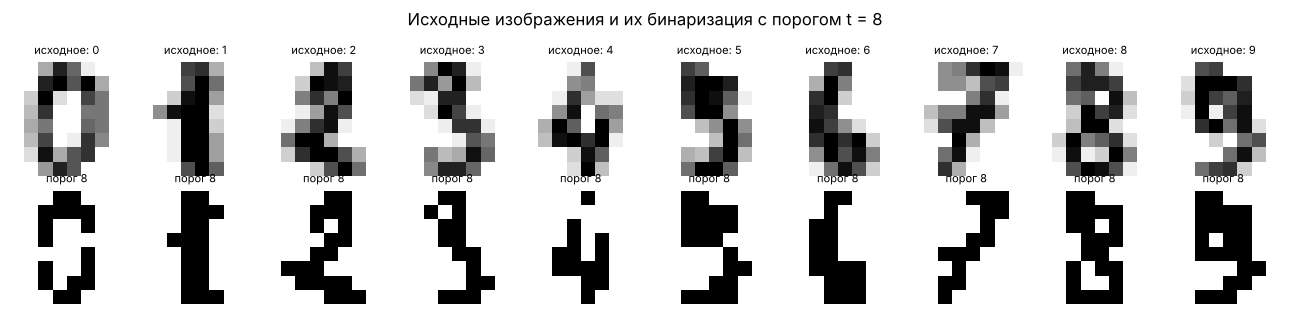

In [2]:
digits = load_digits()
X, y = digits.data, digits.target
print("Размер X:", X.shape, "| диапазон значений:", X.min(), "...", X.max())
print("Баланс классов:", np.bincount(y))

fig, axes = plt.subplots(2, 10, figsize=(13, 3.2))
for i, ax in enumerate(axes[0]):
    idx = np.where(y == i)[0][0]
    ax.imshow(X[idx].reshape(8, 8), cmap="gray_r"); ax.set_title(f"исходное: {i}", fontsize=8); ax.axis("off")
for i, ax in enumerate(axes[1]):
    idx = np.where(y == i)[0][0]
    ax.imshow((X[idx] > 8).reshape(8, 8), cmap="gray_r"); ax.set_title("порог 8", fontsize=8); ax.axis("off")
plt.suptitle("Исходные изображения и их бинаризация с порогом t = 8")
plt.tight_layout(); plt.show()

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
print("train:", X_train.shape, "| test:", X_test.shape)

train: (1257, 64) | test: (540, 64)


## 3. Собственная реализация и сверка с scikit-learn

Реализация лежит в `src/bernoulli_nb.py` (класс `BernoulliNaiveBayes`). Бинаризация пикселей выполняется параметром `threshold`. Проверим, что наша модель даёт **те же** логарифмы вероятностей и предсказания, что и `BernoulliNB` из sklearn (с тем же порогом и `alpha`).

In [4]:
T, ALPHA = 8, 1.0
my = BernoulliNaiveBayes(alpha=ALPHA, threshold=T).fit(X_train, y_train)
sk = BernoulliNB(alpha=ALPHA, binarize=T).fit(X_train, y_train)

acc_my, acc_sk = my.score(X_test, y_test), sk.score(X_test, y_test)
max_diff = np.abs(my.predict_log_proba(X_test) - sk.predict_log_proba(X_test)).max()
same_pred = (my.predict(X_test) == sk.predict(X_test)).all()

print(f"Accuracy (своя реализация): {acc_my:.4f}")
print(f"Accuracy (sklearn)        : {acc_sk:.4f}")
print(f"Макс. |разница log P|     : {max_diff:.2e}")
print(f"Предсказания совпали      : {same_pred}")
assert same_pred and max_diff < 1e-8

Accuracy (своя реализация): 0.8741
Accuracy (sklearn)        : 0.8741
Макс. |разница log P|     : 5.68e-14
Предсказания совпали      : True


Реализации совпадают с точностью до ошибок округления. Дальше эксперименты проводим со своей моделью.

## 4. Влияние порога бинаризации

Пиксели принимают значения 0…16. Переберём порог $t = 0,1,\dots,15$ (пиксель = 1, если его значение $>t$) и оценим качество 5-кратной кросс-валидацией **на обучающей выборке** (тест остаётся нетронутым для финальной оценки).

Лучший порог по CV: t = 7, accuracy = 0.8926


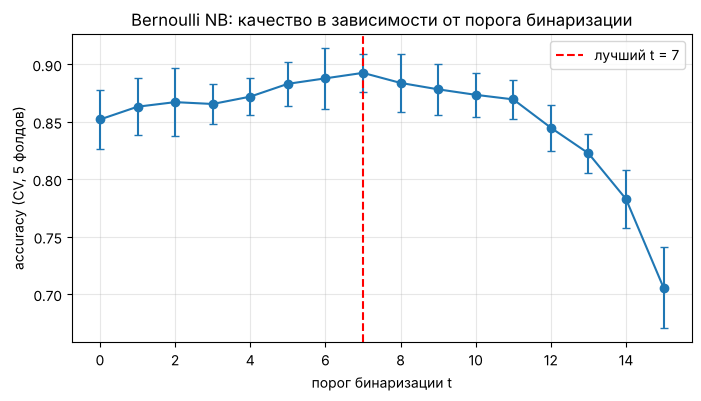

t,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
cv_accuracy,0.8520,0.8632,0.8672,0.8655,0.8719,0.8831,0.8879,0.8926,0.8839,0.8783,0.8735,0.8695,0.8449,0.8226,0.7828,0.7057
std,0.0255,0.0248,0.0298,0.0171,0.0162,0.0191,0.0263,0.0168,0.0251,0.0221,0.0192,0.0171,0.0199,0.0171,0.0253,0.0351


In [5]:
thresholds = np.arange(0, 16)
cv_mean, cv_std = [], []
for t in thresholds:
    scores = cross_val_score(BernoulliNaiveBayes(alpha=1.0, threshold=t), X_train, y_train, cv=cv)
    cv_mean.append(scores.mean()); cv_std.append(scores.std())
cv_mean, cv_std = np.array(cv_mean), np.array(cv_std)

best_t = thresholds[cv_mean.argmax()]
print(f"Лучший порог по CV: t = {best_t}, accuracy = {cv_mean.max():.4f}")

plt.figure(figsize=(8, 4))
plt.errorbar(thresholds, cv_mean, yerr=cv_std, marker="o", capsize=3)
plt.axvline(best_t, color="r", ls="--", label=f"лучший t = {best_t}")
plt.xlabel("порог бинаризации t"); plt.ylabel("accuracy (CV, 5 фолдов)")
plt.title("Bernoulli NB: качество в зависимости от порога бинаризации")
plt.legend(); plt.show()

pd.DataFrame({"t": thresholds, "cv_accuracy": cv_mean.round(4), "std": cv_std.round(4)}).set_index("t").T

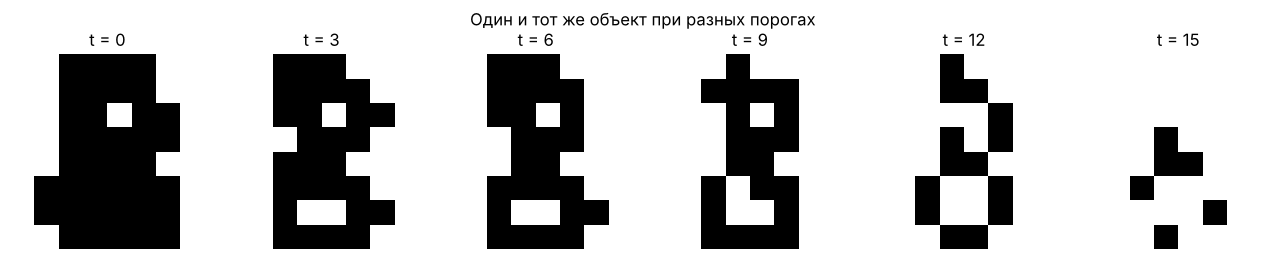

In [6]:
fig, axes = plt.subplots(1, 6, figsize=(13, 2.6))
sample = X[y == 8][0]
for ax, t in zip(axes, [0, 3, 6, 9, 12, 15]):
    ax.imshow((sample > t).reshape(8, 8), cmap="gray_r"); ax.set_title(f"t = {t}"); ax.axis("off")
plt.suptitle("Один и тот же объект при разных порогах"); plt.tight_layout(); plt.show()

**Наблюдение.** При $t=0$ в «чернилах» оказывается любой ненулевой пиксель, при $t=15$ — только максимально тёмные: в обоих крайних случаях изображение теряет форму и качество падает. Хорошо работает порог в средней части диапазона, где сохраняется контур цифры.

## 5. Влияние параметра сглаживания `alpha`

Без сглаживания ($\alpha=0$) пиксель, который ни разу не был «1» (или всегда был «1») в обучении для класса, даёт $\theta\in\{0,1\}$ и $\log 0=-\infty$: одно «неожиданное» значение обнуляет вероятность класса. Сглаживание это исправляет. Посмотрим на зависимость от $\alpha$ при лучшем пороге.

Лучший alpha по CV: 0.1, accuracy = 0.8942


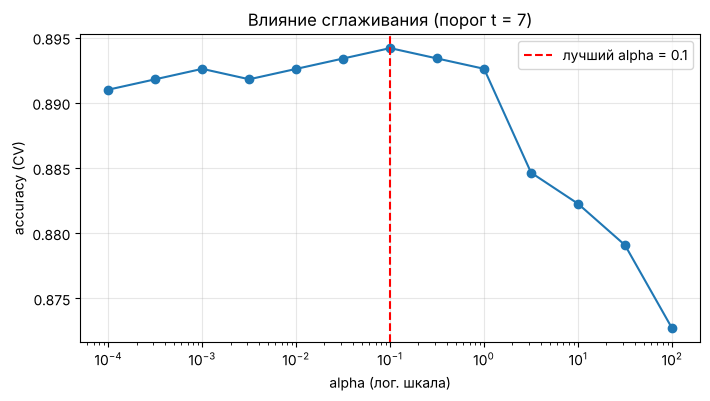

In [7]:
alphas = np.logspace(-4, 2, 13)
a_mean = np.array([cross_val_score(BernoulliNaiveBayes(alpha=a, threshold=best_t), X_train, y_train, cv=cv).mean()
                   for a in alphas])
best_alpha = alphas[a_mean.argmax()]
print(f"Лучший alpha по CV: {best_alpha:.4g}, accuracy = {a_mean.max():.4f}")

plt.figure(figsize=(8, 4))
plt.semilogx(alphas, a_mean, marker="o")
plt.axvline(best_alpha, color="r", ls="--", label=f"лучший alpha = {best_alpha:.3g}")
plt.xlabel("alpha (лог. шкала)"); plt.ylabel("accuracy (CV)")
plt.title(f"Влияние сглаживания (порог t = {best_t})"); plt.legend(); plt.show()

Очень малые $\alpha$ ухудшают результат из-за «жёстких» вероятностей, очень большие — «размывают» $\theta$ к 0.5, и модель перестаёт различать классы. Оптимум лежит между этими крайностями.

## 6. Сравнение с другими моделями

Финальная оценка на отложенной тестовой выборке. Сравниваем:
- **Bernoulli NB** на бинаризованных признаках (подобранные `t` и `alpha`);
- **Bernoulli NB без нормальной бинаризации**: `t = 0` (любой ненулевой пиксель = 1) — как «наивная» бинаризация;
- **Gaussian NB** и **Multinomial NB** на исходных признаках;
- **Логистическая регрессия** на тех же бинарных признаках (более сильная модель, без допущения о независимости).

In [8]:
Xb_train = (X_train > best_t).astype(float)
Xb_test = (X_test > best_t).astype(float)

models = {
    f"Bernoulli NB (t={best_t}, alpha={best_alpha:.2g})": (BernoulliNaiveBayes(alpha=best_alpha, threshold=best_t), X_train, X_test),
    "Bernoulli NB (t=0, alpha=1)":                         (BernoulliNaiveBayes(alpha=1.0, threshold=0), X_train, X_test),
    "Gaussian NB (исходные признаки)":                     (GaussianNB(), X_train, X_test),
    "Multinomial NB (исходные признаки)":                  (MultinomialNB(alpha=1.0), X_train, X_test),
    f"LogReg (бинарные признаки, t={best_t})":             (LogisticRegression(max_iter=2000), Xb_train, Xb_test),
}
rows = []
for name, (model, Xtr, Xte) in models.items():
    model.fit(Xtr, y_train)
    rows.append({"модель": name,
                 "CV accuracy (train)": cross_val_score(model, Xtr, y_train, cv=cv).mean(),
                 "test accuracy": accuracy_score(y_test, model.predict(Xte))})
results = pd.DataFrame(rows).set_index("модель").round(4).sort_values("test accuracy", ascending=False)
results

,CV accuracy (train),test accuracy
модель,,
"LogReg (бинарные признаки, t=7)",0.9284,0.9222
"Bernoulli NB (t=7, alpha=0.1)",0.8942,0.8852
Multinomial NB (исходные признаки),0.9014,0.8759
"Bernoulli NB (t=0, alpha=1)",0.8520,0.8407
Gaussian NB (исходные признаки),0.8441,0.8222


Bernoulli NB на бинаризованных пикселях (≈0.885 на тесте) лучше Gaussian NB (≈0.82) и немного лучше Multinomial NB на исходных данных, причём выбор порога существенен: при $t=0$ результат заметно хуже (≈0.84). Логистическая регрессия на тех же бинарных признаках впереди (≈0.92): ей не мешает зависимость между соседними пикселями — это цена «наивного» допущения.

## 7. Анализ ошибок и интерпретация модели

              precision    recall  f1-score   support

           0      1.000     0.963     0.981        54
           1      0.759     0.745     0.752        55
           2      0.810     0.887     0.847        53
           3      1.000     0.818     0.900        55
           4      0.944     0.944     0.944        54
           5      0.906     0.873     0.889        55
           6      0.981     0.963     0.972        54
           7      0.885     1.000     0.939        54
           8      0.833     0.769     0.800        52
           9      0.774     0.889     0.828        54

    accuracy                          0.885       540
   macro avg      0.889     0.885     0.885       540
weighted avg      0.890     0.885     0.885       540



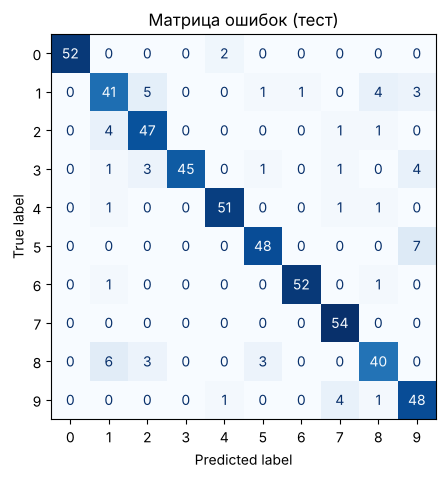

In [9]:
best_model = BernoulliNaiveBayes(alpha=best_alpha, threshold=best_t).fit(X_train, y_train)
y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, digits=3))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.grid(False); ax.set_title("Матрица ошибок (тест)"); plt.show()

Параметры $\theta_{kj}=P(\text{пиксель } j \text{ «чёрный»}\mid \text{цифра } k)$ можно нарисовать как картинки 8×8 — это «усреднённый образ» каждого класса, на котором модель и основывает решения.

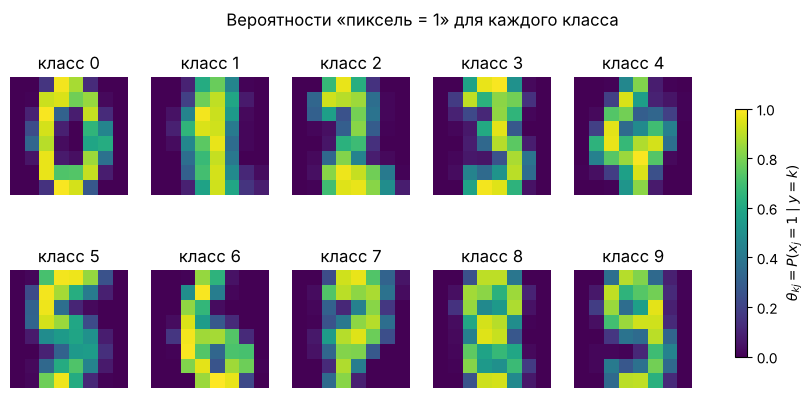

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(11, 4.6))
for k, ax in enumerate(axes.ravel()):
    im = ax.imshow(best_model.theta_[k].reshape(8, 8), cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"класс {k}"); ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.7, label=r"$\theta_{kj}=P(x_j=1\mid y=k)$")
plt.suptitle("Вероятности «пиксель = 1» для каждого класса"); plt.show()

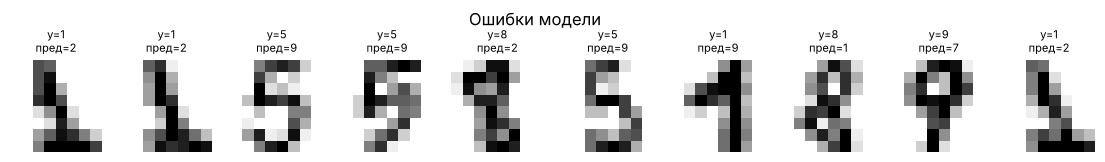

In [11]:
# Примеры ошибочно классифицированных тестовых объектов
wrong = np.where(y_pred != y_test)[0][:10]
fig, axes = plt.subplots(1, max(len(wrong), 1), figsize=(1.4 * max(len(wrong), 1), 2))
for ax, i in zip(np.atleast_1d(axes), wrong):
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"y={y_test[i]}\nпред={y_pred[i]}", fontsize=8); ax.axis("off")
plt.suptitle("Ошибки модели"); plt.show()

## 8. Второй датасет: бинаризация по медиане признака

В `load_breast_cancer` 30 вещественных признаков с разными масштабами (площадь ~ 10³, гладкость ~ 10⁻¹), поэтому единый порог бессмыслен. Бинаризуем **каждый признак по своей медиане, вычисленной на обучающей выборке** (`MedianBinarizer`): значение > медианы → 1. Так признак становится «выше/ниже типичного», а утечки из теста нет — медианы считаются только в `fit`.

In [12]:
bc = load_breast_cancer()
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(bc.data, bc.target, test_size=0.3, stratify=bc.target, random_state=RANDOM_STATE)

pipelines = {
    "Median-бинаризация + Bernoulli NB": make_pipeline(MedianBinarizer(), BernoulliNaiveBayes(alpha=1.0)),
    "Median-бинаризация + BernoulliNB (sklearn)": make_pipeline(MedianBinarizer(), BernoulliNB(alpha=1.0)),
    "Единый порог 0 + Bernoulli NB (бессмысленно)": make_pipeline(Binarizer(threshold=0.0), BernoulliNB(alpha=1.0)),
    "Gaussian NB (исходные признаки)": GaussianNB(),
}
rows = []
for name, p in pipelines.items():
    p.fit(Xc_tr, yc_tr)
    rows.append({"модель": name,
                 "CV accuracy (train)": cross_val_score(p, Xc_tr, yc_tr, cv=cv).mean(),
                 "test accuracy": p.score(Xc_te, yc_te)})
pd.DataFrame(rows).set_index("модель").round(4)

,CV accuracy (train),test accuracy
модель,,
Median-бинаризация + Bernoulli NB,0.9146,0.9123
Median-бинаризация + BernoulliNB (sklearn),0.9146,0.9123
Единый порог 0 + Bernoulli NB (бессмысленно),0.6282,0.6257
Gaussian NB (исходные признаки),0.9271,0.9474


In [13]:
# Какие признаки сильнее всего различают классы после бинаризации?
pipe = pipelines["Median-бинаризация + Bernoulli NB"]
theta = pipe[-1].theta_                       # shape (2, 30); класс 0 = malignant, 1 = benign
gap = np.abs(theta[0] - theta[1])
top = np.argsort(gap)[::-1][:8]
pd.DataFrame({"признак": bc.feature_names[top],
              "P(1|malignant)": theta[0, top].round(3),
              "P(1|benign)": theta[1, top].round(3),
              "разница": gap[top].round(3)}).reset_index(drop=True)

,признак,P(1|malignant),P(1|benign),разница
0,worst perimeter,0.967,0.222,0.744
1,worst area,0.960,0.226,0.734
2,worst radius,0.960,0.226,0.734
3,worst concave points,0.953,0.230,0.723
4,mean concave points,0.953,0.230,0.723
5,worst concavity,0.920,0.250,0.670
6,mean concavity,0.920,0.250,0.670
7,mean perimeter,0.913,0.254,0.659


Даже после грубой бинаризации («выше/ниже медианы») Bernoulli NB даёт точность ≈0.91, хотя Gaussian NB на исходных признаках здесь лучше (≈0.95): бинаризация теряет часть информации, а Gaussian NB её сохраняет и для этих данных подходит. Наиболее различающие классы признаки — размерные характеристики опухоли (радиус, периметр, площадь, вогнутость); они сильно коррелируют, поэтому их $\theta$ почти совпадают — ещё одно проявление нарушения «наивного» допущения. Единый порог на несопоставимых масштабах разрушает информацию (≈0.63).

## 9. Выводы

1. Bernoulli NB — простая и быстрая модель (обучение = подсчёт частот), хорошо подходящая для бинарных признаков. Собственная реализация совпадает с `sklearn.naive_bayes.BernoulliNB` до ошибок округления.
2. **Бинаризация — ключевой гиперпараметр.** Слишком низкий/высокий порог уничтожает информацию; порог нужно подбирать кросс-валидацией на обучающей выборке. Для признаков разного масштаба разумнее бинаризовать каждый признак отдельно (например, по медиане из `train`).
3. **Сглаживание `alpha`** защищает от нулевых вероятностей; очень малые и очень большие значения ухудшают качество.
4. Отсутствие признака (0) учитывается моделью явно, что отличает Bernoulli NB от Multinomial NB.
5. Ошибки предобработки: `BernoulliNB` без указания `binarize` молча использует порог 0, а пороги надо настраивать внутри `Pipeline` на обучающей части; утечка медиан на `breast_cancer` заметного смещения не дала (≈ −0,3 п.п. при разбросе 0,8 п.п.), но принцип от этого не меняется.
6. Ограничения: допущение независимости признаков (соседние пиксели сильно коррелируют) и потеря информации при бинаризации — поэтому логистическая регрессия на тех же признаках обычно точнее.